
# Making better use of the external Tg data

*Author: Suhmi. Builds on notebooks 07, 10 and 11.*

## Purpose

In notebook 10, the external Tg data (LAMALAB, 7,194 cleaned polymers) lowered the Tg MAE from
48.2 to 44.9 °C, but only with a **source flag**, because the external values are systematically
higher than ours. This notebook tests four ways to use the external data better:

1. **Scale + offset correction:** map the external values onto our scale with a fitted line
   (a × Tg + b) instead of a constant shift.
2. **Lower weight for the external data:** each external polymer counts less than one of ours.
3. **Multi-task network:** external Tg is a separate, related output of the network (a 6th target).
4. **Retuning:** XGBoost settings searched for the combined data (by MAE).

## Rules

- 73 descriptors + fingerprints; the cleaned external data from notebook 10.
- Every score is calculated on **our** 408 Tg training polymers with the same five folds.
  External polymers are only used for training. **The validation subsets are frozen.**
- Many variants are compared on the same folds, so the best one is slightly optimistic.


## 1. Setup

In [1]:

import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from rdkit import Chem, RDLogger
from scipy.stats import loguniform, randint, uniform
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import KFold, ParameterSampler, train_test_split
from sklearn.pipeline import make_pipeline
from xgboost import XGBRegressor

# Make the project's src package importable from the notebooks folder
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.multitask_network import fit_network
from src.polymer_features import SHAPE_COLUMNS, build_chain_features, build_features

RDLogger.DisableLog("rdApp.*")
torch.set_num_threads(8)

RANDOM_STATE = 42
VALIDATION_FRACTION = 0.20
N_FOLDS = 5

target_columns = ["Tg", "FFV", "Tc", "Density", "Rg"]
TG = target_columns.index("Tg")


## 2. Data, features, splits and folds

In [2]:

train = pd.read_csv(PROJECT_ROOT / "data" / "raw" / "train.csv")
external = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "external_tg_clean.csv")


def feature_table(smiles, shape):
    bplus, fingerprints = build_features(smiles)
    chain = build_chain_features(smiles)
    return pd.concat([bplus, chain, shape], axis=1), fingerprints


shape_ours = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "shape_descriptors.csv",
                         index_col=0)[SHAPE_COLUMNS]
descriptors_ours, fingerprints_ours = feature_table(train["SMILES"], shape_ours)
descriptors_ext, fingerprints_ext = feature_table(external["SMILES"], external[SHAPE_COLUMNS])

X_ours = pd.concat([descriptors_ours, fingerprints_ours], axis=1).to_numpy(dtype=float)
X_ext = pd.concat([descriptors_ext, fingerprints_ext], axis=1).to_numpy(dtype=float)
y_ext = external["Tg"].to_numpy()
print("Features:", X_ours.shape[1], "| our polymers:", len(X_ours), "| external polymers:", len(X_ext))

cv_folds = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
labels = train[target_columns].to_numpy(dtype=float)
train_rows, fold_rows = {}, {}
for target in target_columns:
    labelled = train.index[train[target].notna()]
    train_index, _ = train_test_split(
        labelled, test_size=VALIDATION_FRACTION, random_state=RANDOM_STATE, shuffle=True
    )
    train_rows[target] = np.asarray(train_index)
    fold_rows[target] = [train_rows[target][test_idx] for _, test_idx in cv_folds.split(train_index)]
expected_sizes = {"Tg": 408, "FFV": 5624, "Tc": 589, "Density": 490, "Rg": 491}
assert {t: len(rows) for t, rows in train_rows.items()} == expected_sizes
tg_train, tg_folds = train_rows["Tg"], fold_rows["Tg"]

default_params = dict(n_estimators=500, learning_rate=0.05, max_depth=4, subsample=0.8,
                      colsample_bytree=0.8)


def xgboost(params):
    return make_pipeline(SimpleImputer(strategy="median"),
                         XGBRegressor(**params, random_state=RANDOM_STATE, n_jobs=-1))


def score(fold, y_pred):
    rows = tg_folds[fold]
    fit_rows = np.setdiff1d(tg_train, rows)
    y_true = labels[rows, TG]
    baseline = np.mean(np.abs(y_true - np.median(labels[fit_rows, TG])))
    mae = mean_absolute_error(y_true, y_pred)
    return {"fold": fold, "MAE": mae, "error_reduction": 100 * (1 - mae / baseline),
            "R2": r2_score(y_true, y_pred), "mean_error": np.mean(y_pred - y_true)}


def summarise(rows):
    return pd.DataFrame(rows).groupby("variant", sort=False).agg(
        MAE=("MAE", "mean"), error_reduction=("error_reduction", "mean"),
        error_reduction_std=("error_reduction", "std"), R2=("R2", "mean"),
        mean_error=("mean_error", "mean"))


flag_ours, flag_ext = np.zeros((len(X_ours), 1)), np.ones((len(X_ext), 1))
X_ours_flag, X_ext_flag = np.hstack([X_ours, flag_ours]), np.hstack([X_ext, flag_ext])
oof = {}


Features: 1097 | our polymers: 7973 | external polymers: 7194



## 3. Scale + offset correction and lower weights

**Scale + offset:** in every fold, a model trained on the external data alone predicts our
fitting polymers; a straight line *our Tg ≈ a × predicted + b* is fitted on these (never on the
evaluated polymers) and applied to the external labels. The corrected external data is then
added, with and without the source flag.

**Weights:** the external polymers get the sample weight 0.1, 0.3 or 0.5 (ours: 1),
together with the source flag.


In [3]:

external_only = xgboost(default_params).fit(X_ext, y_ext)
pred_from_external = external_only.predict(X_ours)   # external polymers contain none of our Tg polymers

variants = ["Our data only", "External + flag (notebook 10)",
            "External scaled", "External scaled + flag",
            "External + flag, weight 0.1", "External + flag, weight 0.3", "External + flag, weight 0.5"]
results, lines = [], []
start = time.time()
for fold in range(N_FOLDS):
    rows = tg_folds[fold]
    fit_rows = np.setdiff1d(tg_train, rows)
    y_fit = labels[fit_rows, TG]
    a, b = np.polyfit(pred_from_external[fit_rows], y_fit, 1)
    lines.append({"fold": fold, "a": a, "b": b})
    y_ext_scaled = a * y_ext + b

    for variant in variants:
        if variant == "Our data only":
            X_fit, y, weights, X_eval = X_ours[fit_rows], y_fit, None, X_ours[rows]
        else:
            flagged = "flag" in variant
            X_a = X_ours_flag if flagged else X_ours
            X_b = X_ext_flag if flagged else X_ext
            X_fit = np.vstack([X_a[fit_rows], X_b])
            y = np.concatenate([y_fit, y_ext_scaled if "scaled" in variant else y_ext])
            weight = float(variant.split("weight ")[1]) if "weight" in variant else 1.0
            weights = np.concatenate([np.ones(len(fit_rows)), np.full(len(X_ext), weight)])
            X_eval = X_a[rows]
        model = xgboost(default_params).fit(X_fit, y, xgbregressor__sample_weight=weights)
        y_pred = model.predict(X_eval)
        oof.setdefault(variant, pd.Series(index=tg_train, dtype=float)).loc[rows] = y_pred
        results.append({"variant": variant, **score(fold, y_pred)})
    print(f"Fold {fold + 1} done ({time.time() - start:.0f} s)")

display(pd.DataFrame(lines).round(2))
summary_xgb = summarise(results)
display(summary_xgb.round(2))


Fold 1 done (14 s)


Fold 2 done (28 s)


Fold 3 done (43 s)


Fold 4 done (57 s)


Fold 5 done (71 s)


,fold,a,b
0,0,0.97,-18.56
1,1,0.94,-18.38
2,2,0.96,-20.33
3,3,0.95,-21.59
4,4,0.93,-17.43


,MAE,error_reduction,error_reduction_std,R2,mean_error
variant,,,,,
Our data only,50.60,42.93,4.24,0.66,-0.20
External + flag (notebook 10),44.86,49.43,4.53,0.72,4.15
External scaled,45.85,48.30,4.85,0.71,0.19
External scaled + flag,45.48,48.71,4.23,0.71,0.38
"External + flag, weight 0.1",45.36,48.84,2.74,0.71,3.29
"External + flag, weight 0.3",45.29,48.93,3.58,0.71,3.85
"External + flag, weight 0.5",44.78,49.50,3.48,0.72,3.62



## 4. Multi-task network with external Tg as a 6th target

The network from notebooks 05–07 (73 descriptors) gets a sixth output, **external Tg**.
External polymers that are in our data get this label in their own row; the others are added as
new rows with only this label. The network learns shared chemistry from both Tg sources, while our
Tg output keeps our scale. The ensemble averages the network with the best XGBoost variant so far.


In [4]:

canonical_ours = train["SMILES"].apply(lambda s: Chem.MolToSmiles(Chem.MolFromSmiles(s)))
row_of = pd.Series(train.index, index=canonical_ours).groupby(level=0).first()
in_ours = external["canonical"].isin(row_of.index).to_numpy()

# Network inputs: our polymers, followed by the external polymers that are not in our data
X_net = np.vstack([descriptors_ours.to_numpy(dtype=float),
                   descriptors_ext.to_numpy(dtype=float)[~in_ours]])
external_column = np.full(len(X_net), np.nan)
external_column[row_of.loc[external.loc[in_ours, "canonical"]].to_numpy()] = y_ext[in_ours]
external_column[len(train):] = y_ext[~in_ours]
print(f"Network rows: {len(X_net)} ({len(train)} ours + {(~in_ours).sum()} external only); "
      f"external Tg labels: {np.isfinite(external_column).sum()}")

best_xgb = summary_xgb["MAE"].idxmin()
print("Best XGBoost variant so far:", best_xgb)

net_results = []
start = time.time()
for fold in range(N_FOLDS):
    Y = np.full((len(X_net), 6), np.nan)
    for t, target in enumerate(target_columns):
        fit_rows = np.setdiff1d(train_rows[target], fold_rows[target][fold])
        Y[fit_rows, t] = labels[fit_rows, t]
    Y[:, 5] = external_column
    rows = tg_folds[fold]

    for variant, outputs in [("Network, our targets only", 5), ("Network + external Tg target", 6)]:
        Y_used = Y[:, :outputs]
        has_label = ~np.isnan(Y_used).all(axis=1)
        predict = fit_network(X_net[has_label], Y_used[has_label], seed=RANDOM_STATE + fold)
        y_pred = predict(X_net[rows])[:, TG]
        oof.setdefault(variant, pd.Series(index=tg_train, dtype=float)).loc[rows] = y_pred
        net_results.append({"variant": variant, **score(fold, y_pred)})

    y_ens = (oof["Network + external Tg target"].loc[rows] + oof[best_xgb].loc[rows]).to_numpy() / 2
    oof.setdefault("Ensemble: network (+ external) + best XGBoost", pd.Series(index=tg_train, dtype=float)).loc[rows] = y_ens
    net_results.append({"variant": "Ensemble: network (+ external) + best XGBoost", **score(fold, y_ens)})
    print(f"Fold {fold + 1} done ({time.time() - start:.0f} s)")

summary_net = summarise(net_results)
display(summary_net.round(2))


Network rows: 10079 (7973 ours + 2106 external only); external Tg labels: 7194
Best XGBoost variant so far: External + flag, weight 0.5


Fold 1 done (19 s)


Fold 2 done (26 s)


Fold 3 done (34 s)


Fold 4 done (55 s)


Fold 5 done (71 s)


,MAE,error_reduction,error_reduction_std,R2,mean_error
variant,,,,,
"Network, our targets only",52.12,41.24,4.36,0.63,1.69
Network + external Tg target,50.79,42.72,3.45,0.65,1.46
Ensemble: network (+ external) + best XGBoost,45.53,48.65,3.80,0.71,2.54



## 5. Retuning XGBoost for the combined data

25 random settings from the same search ranges as notebook 04, each scored with the five folds
(trained on our fitting polymers + external data with source flag, scored on our polymers),
selected by MAE.


In [5]:

search_space = {
    "n_estimators": randint(200, 1501), "learning_rate": loguniform(0.01, 0.2),
    "max_depth": randint(2, 9), "min_child_weight": randint(1, 11),
    "subsample": uniform(0.6, 0.4), "colsample_bytree": uniform(0.6, 0.4),
    "reg_lambda": loguniform(0.1, 10),
}
external_weight = 1.0
if "weight" in best_xgb:
    external_weight = float(best_xgb.split("weight ")[1])
print("External weight used in the search:", external_weight)

search_rows = []
start = time.time()
for i, params in enumerate(ParameterSampler(search_space, n_iter=25, random_state=RANDOM_STATE)):
    maes = []
    for fold in range(N_FOLDS):
        rows = tg_folds[fold]
        fit_rows = np.setdiff1d(tg_train, rows)
        X_fit = np.vstack([X_ours_flag[fit_rows], X_ext_flag])
        y = np.concatenate([labels[fit_rows, TG], y_ext])
        weights = np.concatenate([np.ones(len(fit_rows)), np.full(len(X_ext), external_weight)])
        y_pred = xgboost(params).fit(X_fit, y, xgbregressor__sample_weight=weights).predict(X_ours_flag[rows])
        maes.append(mean_absolute_error(labels[rows, TG], y_pred))
    search_rows.append({"candidate": i, "MAE": np.mean(maes), **params})
    if (i + 1) % 5 == 0:
        print(f"{i + 1} of 25 settings done ({time.time() - start:.0f} s)")

search_df = pd.DataFrame(search_rows).sort_values("MAE")
display(search_df.head(5).round(4))
tuned_params = {k: search_df.iloc[0][k] for k in search_space}
for k in ["n_estimators", "max_depth", "min_child_weight"]:
    tuned_params[k] = int(tuned_params[k])

tuned_results = []
for fold in range(N_FOLDS):
    rows = tg_folds[fold]
    fit_rows = np.setdiff1d(tg_train, rows)
    X_fit = np.vstack([X_ours_flag[fit_rows], X_ext_flag])
    y = np.concatenate([labels[fit_rows, TG], y_ext])
    weights = np.concatenate([np.ones(len(fit_rows)), np.full(len(X_ext), external_weight)])
    y_pred = xgboost(tuned_params).fit(X_fit, y, xgbregressor__sample_weight=weights).predict(X_ours_flag[rows])
    oof.setdefault("Retuned XGBoost (external + flag)", pd.Series(index=tg_train, dtype=float)).loc[rows] = y_pred
    tuned_results.append({"variant": "Retuned XGBoost (external + flag)", **score(fold, y_pred)})
    y_ens = (oof["Network + external Tg target"].loc[rows].to_numpy() + y_pred) / 2
    oof.setdefault("Ensemble: network (+ external) + retuned XGBoost", pd.Series(index=tg_train, dtype=float)).loc[rows] = y_ens
    tuned_results.append({"variant": "Ensemble: network (+ external) + retuned XGBoost", **score(fold, y_ens)})
summary_tuned = summarise(tuned_results)
display(summary_tuned.round(2))


External weight used in the search: 0.5


5 of 25 settings done (114 s)


10 of 25 settings done (204 s)


15 of 25 settings done (290 s)


20 of 25 settings done (435 s)


25 of 25 settings done (545 s)


,candidate,MAE,colsample_bytree,learning_rate,max_depth,min_child_weight,n_estimators,reg_lambda,subsample
21,21,44.1323,0.7670,0.0195,4,10,883,0.3078,0.6673
5,5,44.3834,0.8721,0.0386,3,4,800,8.5362,0.9234
22,22,44.3949,0.6875,0.0532,5,1,641,8.4119,0.7007
14,14,44.4719,0.8365,0.0228,4,1,812,8.7786,0.9396
3,3,44.5544,0.7728,0.0239,4,10,899,0.5404,0.7824


,MAE,error_reduction,error_reduction_std,R2,mean_error
variant,,,,,
Retuned XGBoost (external + flag),44.13,50.23,3.39,0.73,3.49
Ensemble: network (+ external) + retuned XGBoost,45.28,48.94,3.89,0.71,2.47


## 6. Overview

,MAE,error_reduction,error_reduction_std,R2,mean_error
variant,,,,,
Retuned XGBoost (external + flag),44.13,50.23,3.39,0.73,3.49
"External + flag, weight 0.5",44.78,49.50,3.48,0.72,3.62
External + flag (notebook 10),44.86,49.43,4.53,0.72,4.15
Ensemble: network (+ external) + retuned XGBoost,45.28,48.94,3.89,0.71,2.47
"External + flag, weight 0.3",45.29,48.93,3.58,0.71,3.85
"External + flag, weight 0.1",45.36,48.84,2.74,0.71,3.29
External scaled + flag,45.48,48.71,4.23,0.71,0.38
Ensemble: network (+ external) + best XGBoost,45.53,48.65,3.80,0.71,2.54
External scaled,45.85,48.30,4.85,0.71,0.19


,Our data only,External + flag (notebook 10),Best: Retuned XGBoost (external + flag)
"(-149.0, 5.0]",60.7,60.8,60.3
"(5.0, 51.0]",41.6,35.4,34.8
"(51.0, 107.0]",38.1,35.8,35.3
"(107.0, 185.0]",48.8,43.3,42.7
"(185.0, 472.0]",63.7,49.0,47.5


Slope of predicted vs. actual Tg (best): 0.74


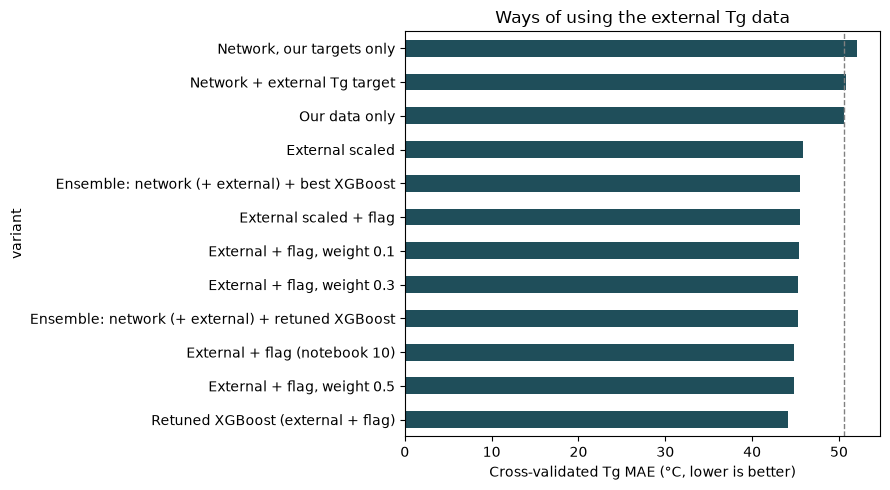

In [6]:

overview = pd.concat([summary_xgb, summary_net, summary_tuned])
display(overview.sort_values("MAE").round(2))

best = overview["MAE"].idxmin()
y_true = pd.Series(labels[tg_train, TG], index=tg_train)
ranges = pd.qcut(y_true, 5, precision=0)
display(pd.DataFrame({
    "Our data only": (oof["Our data only"] - y_true).abs().groupby(ranges, observed=True).mean(),
    "External + flag (notebook 10)": (oof["External + flag (notebook 10)"] - y_true).abs()
        .groupby(ranges, observed=True).mean(),
    f"Best: {best}": (oof[best] - y_true).abs().groupby(ranges, observed=True).mean(),
}).round(1))
print(f"Slope of predicted vs. actual Tg (best): {np.polyfit(y_true, oof[best], 1)[0]:.2f}")

ax = overview["MAE"].sort_values().plot(kind="barh", figsize=(9, 5), color="#1f4e5a")
ax.axvline(overview.loc["Our data only", "MAE"], color="grey", linestyle="--", linewidth=1)
ax.set_xlabel("Cross-validated Tg MAE (°C, lower is better)")
ax.set_title("Ways of using the external Tg data")
plt.tight_layout()
plt.show()


#### Findings: better use of the external Tg data

Cross-validated Tg MAE on our 408 training polymers (lower is better):

| Variant | MAE (°C) | Error reduction | R² |
|---|---:|---:|---:|
| Tuned XGBoost, our data only (notebook 07) | 48.2 | 45.6% | 0.69 |
| External + source flag (notebook 10) | 44.9 | 49.4% | 0.72 |
| 1. External scaled (a × Tg + b), with flag | 45.5 | 48.7% | 0.71 |
| 2. External + flag, weight 0.5 | 44.8 | 49.5% | 0.72 |
| 3. Multi-task network with external Tg target (alone) | 50.8 | 42.7% | 0.65 |
| 3. Ensemble: this network + XGBoost | 45.3 | 48.9% | 0.71 |
| **4. Retuned XGBoost, external + flag, weight 0.5** | **44.1** | **50.2% ± 3.4** | **0.73** |

- **The difference between the datasets is essentially a constant offset.** The fitted line is
  a ≈ 0.95, b ≈ −19 °C in every fold, i.e. our values are about 19–25 °C lower. A constant shift
  (the source flag) is therefore enough; the scale correction brings no extra gain.
- **Lower weights** change little (44.8–45.4 °C).
- **The multi-task network** learns from the external Tg target (52.1 → 50.8 °C), but it stays clearly
  weaker than XGBoost, so it does not improve the ensemble.
- **Retuning** gives the best result, 44.1 °C (−0.8 °C vs. notebook 10). The setting (depth 4,
  883 trees, learning rate 0.02) was selected from 25 candidates on the same folds, so this small gain
  is within the fold-to-fold variation and slightly optimistic.
- Compared with our data only, the external data mainly improves the middle and upper Tg range
  (185–472 °C: 63.7 → 47.5 °C); very low Tg (< 5 °C) stays at about 60 °C.

**Conclusion.** The external data gives a real improvement (about −4 °C, 48.2 → 44.1 °C); the four
refinements add at most about 1 °C. This fits the label-noise estimate of notebook 08 and 10
(the same polymer differs by about 30 °C between sources): the Tg error is now close to what the
labels allow.

**Decision (chosen by cross-validated MAE):** final Tg model = retuned XGBoost on 73 descriptors +
fingerprints, trained on our data + the cleaned external data with source flag (external weight 0.5).
The validation subsets were not used.
